# Galaxy survey vs HI intensity mapping

*Runtime: about 15 s, peak memory: about 3 GB on a MacBook (Apple M2), full notebook.*

We simulate one density field and observe it in two ways: as a galaxy survey (count galaxies; limited by shot noise) and as an HI intensity map (total 21cm emission per pixel; smoothed by the beam).

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

from meer21cm import MockSimulation
from meer21cm.plot import plot_map
from meer21cm.telescope import dish_beam_sigma
from meer21cm.util import redshift_to_freq

# one plotting style for the whole notebook
plt.rcParams.update({
    "font.size": 13,             # default text (e.g. colourbar labels)
    "axes.labelsize": 15,        # axis labels
    "axes.titlesize": 14,        # panel titles
    "xtick.labelsize": 13,       # tick labels
    "ytick.labelsize": 13,
    "legend.fontsize": 12,       # legend entries
    "legend.title_fontsize": 12, # legend title
    "legend.frameon": False,     # legends without a box
})

## 1. Survey set-up

An 80° × 30° patch at $0.4<z<0.6$, with 64 frequency channels and the beam of a 13.5 m MeerKAT dish.

In [2]:
z_min, z_max = 0.4, 0.6
nu = np.linspace(redshift_to_freq(z_max), redshift_to_freq(z_min), 64)  # Hz, 64 channels
nside = 128
ra_range = (140.0, 220.0)   # 80 deg
dec_range = (-30.0, 0.0)    # 30 deg
sigma_beam = dish_beam_sigma(13.5, nu)  # Gaussian beam sigma in deg, per channel

print(f"frequency: {nu.min()/1e6:.1f} - {nu.max()/1e6:.1f} MHz")
print(f"beam FWHM: {sigma_beam.min()*2.355:.2f} - {sigma_beam.max()*2.355:.2f} deg")

frequency: 887.8 - 1014.6 MHz
beam FWHM: 1.25 - 1.43 deg


## 2. One mock universe, two tracers

One lognormal density field gives both the HI temperature and the galaxies, so both maps trace the same structures.

In [3]:
mock = MockSimulation(
    nu=nu,                    # frequency channels [Hz]
    hp_nside=nside,           # HEALPix resolution
    ra_range=ra_range,        # sky patch [deg]
    dec_range=dec_range,
    sigma_beam_ch=sigma_beam, # beam width per channel [deg]
    mean_amp_1="average_hi_temp",  # HI field in K
    omega_hi=5e-4,            # HI density
    tracer_bias_1=1.5,        # HI bias
    tracer_bias_2=1.9,        # galaxy bias
    downres_factor_transverse=0.5,  # simulation cells finer than the map pixels
    downres_factor_radial=0.5,
    seed=42,                  # random seed, for reproducible mocks
)
n_gal = 3e-4  # galaxy number density [Mpc^-3]
mock.num_discrete_source = int(n_gal * mock.survey_volume)  # number of galaxies

print(f"{mock.pixel_id.size} HEALPix pixels, {mock.pixel_id.size * mock.pixel_area:.0f} deg^2")
print(f"survey volume: {mock.survey_volume/1e9:.2f} Gpc^3")

10782 HEALPix pixels, 2262 deg^2
survey volume: 1.78 Gpc^3


## 3. Observe it

Project the HI onto the sky pixels with the beam, and draw a galaxy catalogue and count galaxies per pixel.

In [4]:
%%time
# HI map cube (pixel, channel) in K, with the beam
hi_cube = mock.propagate_mock_field_to_data(mock.mock_tracer_field_1)

# galaxy catalogue
mock.propagate_mock_tracer_to_gal_cat()
print(f"{mock.ra_gal.size} galaxies, z = {mock.z_gal.min():.3f} - {mock.z_gal.max():.3f}")

541852 galaxies, z = 0.399 - 0.602
CPU times: user 12.5 s, sys: 1.37 s, total: 13.9 s
Wall time: 8.43 s


In [5]:
# HI: average over all frequency channels, in mK
hi_map = hi_cube.mean(axis=-1) * 1e3

# galaxies: counts per pixel
gal_pix = hp.ang2pix(nside, mock.ra_gal, mock.dec_gal, lonlat=True)
gal_counts_full = np.bincount(gal_pix, minlength=hp.nside2npix(nside))
gal_map = gal_counts_full[mock.pixel_id]

print(f"mean galaxies per pixel: {gal_map.mean():.1f}")

mean galaxies per pixel: 49.6


## 4. Compare

**(A)** HI: smooth, set by the ~1° beam. **(B)** Galaxies: sharper but noisy. Look for the same structures in both.

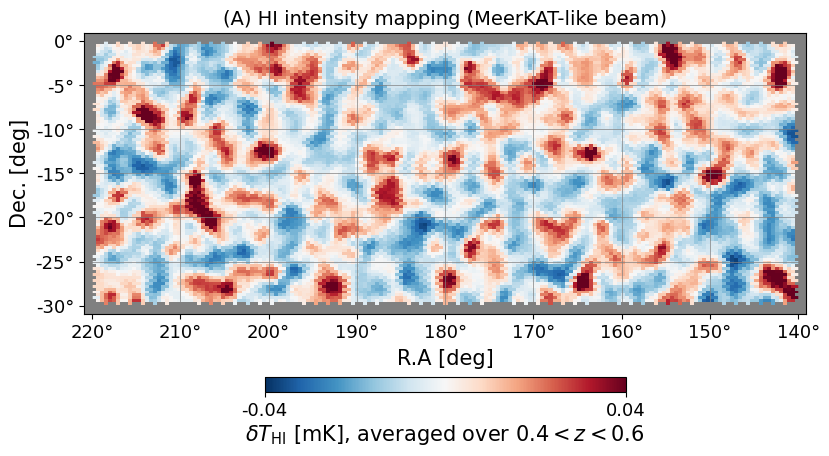

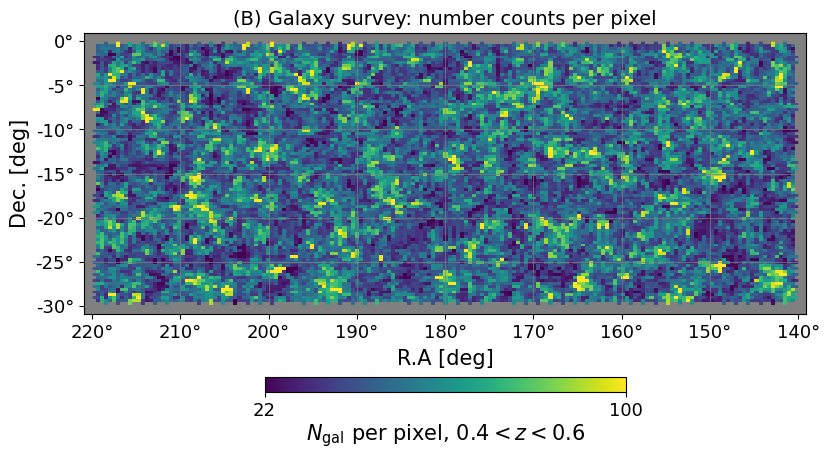

In [6]:
plot_kw = dict(pixel_id=mock.pixel_id, hp_nside=nside, ra_range=ra_range, dec_range=dec_range, dpi=100)

lim = float(f"{np.percentile(np.abs(hi_map), 99):.1g}")  # symmetric colour scale, rounded
plot_map(hi_map, cmap="RdBu_r", vmin=-lim, vmax=lim,
         title="(A) HI intensity mapping (MeerKAT-like beam)",
         cbar_label=r"$\delta T_{\rm HI}$ [mK], averaged over $0.4<z<0.6$", **plot_kw)
# plt.savefig("hi_intensity_map.png", dpi=200, bbox_inches="tight")
plt.show()

plot_map(gal_map, cmap="viridis",
         vmin=np.percentile(gal_map, 1), vmax=np.percentile(gal_map, 99),
         title="(B) Galaxy survey: number counts per pixel",
         cbar_label=r"$N_{\rm gal}$ per pixel, $0.4<z<0.6$", **plot_kw)
# plt.savefig("galaxy_count_map.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Foregrounds and PCA cleaning

Galactic foregrounds are thousands of times brighter than the HI. We simulate them, smooth them with the same beam and add them to the HI.

In [7]:
from meer21cm.fg import ForegroundSimulation
from meer21cm.util import pca_clean

fg_sim = ForegroundSimulation(
    hp_nside=nside,                     # HEALPix resolution
    backend="pysm",                     # PySM3 Galactic sky model
    pysm_preset_strings=["s1", "f1"],   # components: s1 synchrotron, f1 free-free
)
fg_full = fg_sim.fg_wcs_cube(nu)     # full-sky maps [K]
fg_cube = fg_full[:, mock.pixel_id].T  # survey pixels, same layout as hi_cube

# smooth the foregrounds with the same per-channel beam as the HI
fg_cube, _ = mock.convolve_data(
    kernel=None,                     # None: Gaussian beam from sigma_beam_ch
    data=fg_cube,                    # map cube to smooth
    weights=np.ones_like(fg_cube),   # uniform pixel weights
    assign_to_self=False,            # return the result, keep mock.data
)

obs_cube = hi_cube + fg_cube         # observed sky [K]
print(f"foregrounds: {fg_cube.mean():.2f} K on average;  HI fluctuations: {hi_cube.std()*1e3:.3f} mK rms")

foregrounds: 1.05 K on average;  HI fluctuations: 0.068 mK rms


**PCA cleaning** removes the 3 strongest frequency modes, which hold the smooth foregrounds. Some HI is removed with them (signal loss).

In [8]:
res_cube = pca_clean(
    obs_cube,          # observed cube
    3,                 # N_fg: number of eigenmodes removed
    mean_center=True,  # subtract the mean of each channel
)
print(f"rms: residual {res_cube.std()*1e3:.3f} mK,  input HI {hi_cube.std()*1e3:.3f} mK")

rms: residual 0.062 mK,  input HI 0.068 mK


**Maps averaged over frequency.** The observed sky **(C)** is all foregrounds. The cleaned map **(D)** is fainter than the input HI **(A′)**: PCA also removes the HI that varies slowly with frequency.

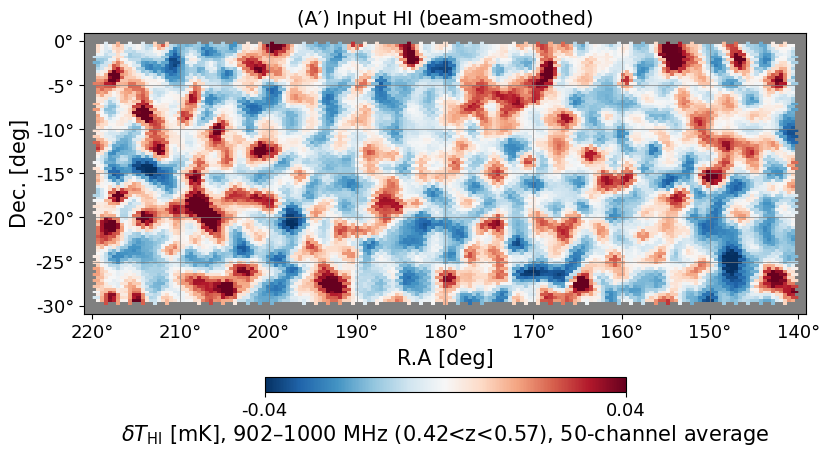

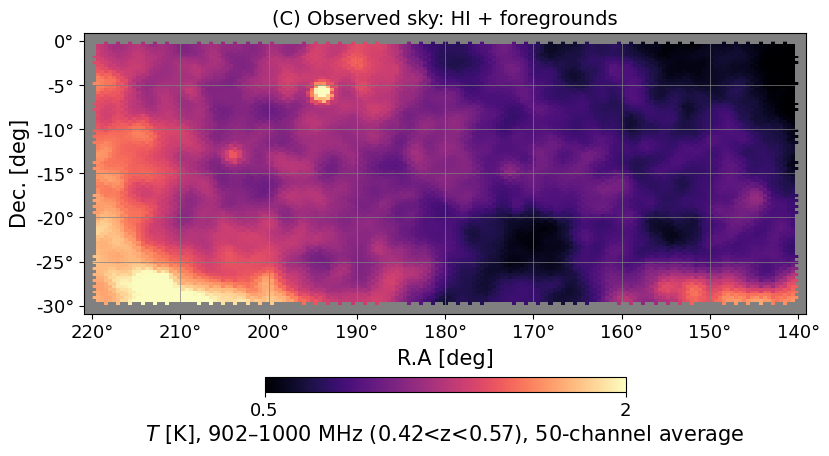

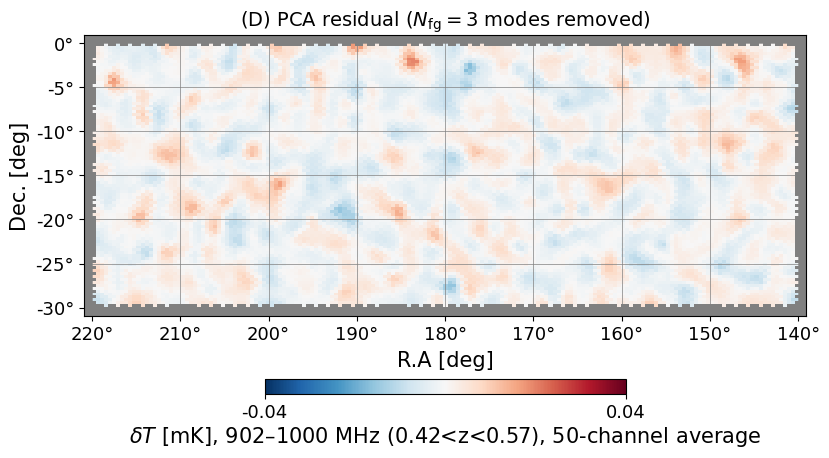

In [9]:
n_avg = 50                                    # number of channels to average
ch0 = (nu.size - n_avg) // 2                  # central 50 channels
ch_sel = slice(ch0, ch0 + n_avg)              # channels ch0 ... ch0 + 49
z_lo, z_hi = 1420.405751e6 / nu[ch_sel][[-1, 0]] - 1
avg_label = (rf"{nu[ch_sel].min()/1e6:.0f}–{nu[ch_sel].max()/1e6:.0f} MHz "
             rf"({z_lo:.2f}<z<{z_hi:.2f}), {n_avg}-channel average")

hi_avg = hi_cube[:, ch_sel].mean(axis=-1) * 1e3   # [mK]
obs_avg = obs_cube[:, ch_sel].mean(axis=-1)       # [K]
res_avg = res_cube[:, ch_sel].mean(axis=-1) * 1e3 # [mK]

lim_avg = float(f"{np.percentile(np.abs(hi_avg), 99):.1g}")  # shared colour scale [mK]

plot_map(hi_avg, cmap="RdBu_r", vmin=-lim_avg, vmax=lim_avg,
         title="(A′) Input HI (beam-smoothed)",
         cbar_label=rf"$\delta T_{{\rm HI}}$ [mK], {avg_label}", **plot_kw)
# plt.savefig("hi_channel_average.png", dpi=200, bbox_inches="tight")
plt.show()

obs_lim = np.round(np.percentile(obs_avg, [1, 99]), 1)  # colour range [K]
plot_map(obs_avg, cmap="magma", vmin=obs_lim[0], vmax=obs_lim[1],
         title="(C) Observed sky: HI + foregrounds",
         cbar_label=rf"$T$ [K], {avg_label}", **plot_kw)
# plt.savefig("observed_channel_average.png", dpi=200, bbox_inches="tight")
plt.show()

plot_map(res_avg, cmap="RdBu_r", vmin=-lim_avg, vmax=lim_avg,
         title=r"(D) PCA residual ($N_{\rm fg}=3$ modes removed)",
         cbar_label=rf"$\delta T$ [mK], {avg_label}", **plot_kw)
# plt.savefig("pca_residual_channel_average.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Gridding to a regular 3D box

For a 3D power spectrum we move the cleaned maps from (pixel, channel) onto a regular grid in comoving Mpc.

In [10]:
# keep the fine simulated HI field before re-gridding
hi_field_hr = mock.mock_tracer_field_1.copy()  # (nx, ny, nz) in K
cell_hr = mock.box_len / mock.box_ndim          # cell size [Mpc]

mock.data = res_cube                 # PCA-cleaned map cube to be gridded
mock.downres_factor_transverse = 1.5 # grid cell = 1.5 x pixel size, transverse
mock.downres_factor_radial = 2.0     # grid cell = 2 x channel width, along the line of sight
res_field, _, res_counts = mock.grid_data_to_field()  # gridded field [K], weights, map voxels per cell
cell_lr = mock.box_len / mock.box_ndim

print("box size [Mpc]:", np.round(mock.box_len))
print("simulation grid:", hi_field_hr.shape, " cell [Mpc]:", np.round(cell_hr, 1))
print("data grid:      ", res_field.shape, " cell [Mpc]:", np.round(cell_lr, 1))

box size [Mpc]: [1284. 2915. 1094.]
simulation grid: (167, 377, 209)  cell [Mpc]: [7.7 7.7 5.2]
data grid:       (55, 125, 53)  cell [Mpc]: [23.3 23.3 20.6]


**(E)** simulated HI on the fine simulation grid; **(F)** the gridded residual, which fills only the observed light cone (black line).

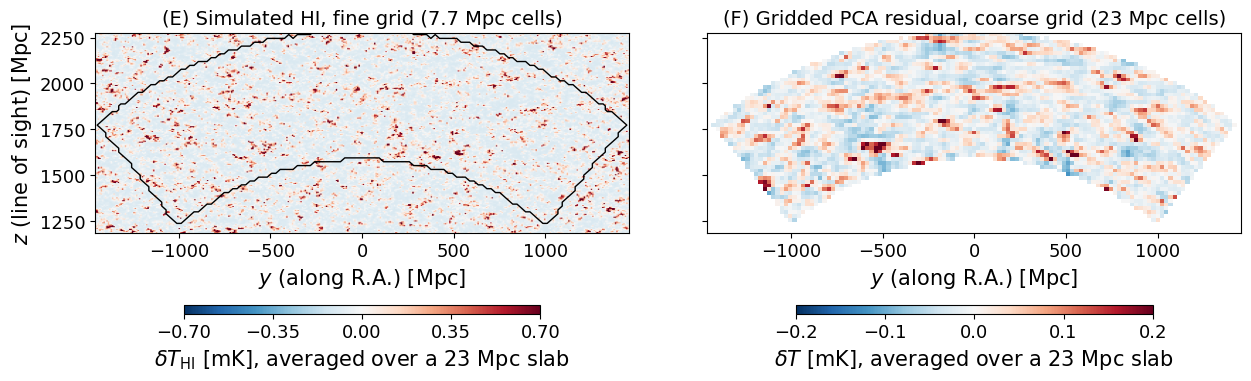

In [11]:
# a slab through the box centre
i_lr = int(mock.box_len[0] / 2 // cell_lr[0])
x_lo, x_hi = i_lr * cell_lr[0], (i_lr + 1) * cell_lr[0]
x_hr = (np.arange(hi_field_hr.shape[0]) + 0.5) * cell_hr[0]
slab_hr = hi_field_hr[(x_hr >= x_lo) & (x_hr < x_hi)].mean(axis=0) * 1e3   # (ny, nz) [mK]
slab_lr = np.where(res_counts[i_lr] > 0, res_field[i_lr], np.nan) * 1e3  # empty cells -> NaN

# axes in Mpc
y0, z0 = mock.box_origin[1], mock.box_origin[2]
extent = [y0, y0 + mock.box_len[1], z0, z0 + mock.box_len[2]]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True, constrained_layout=True)
for ax, slab, title, label in [
    (axes[0], slab_hr, f"(E) Simulated HI, fine grid ({cell_hr[1]:.1f} Mpc cells)", r"$\delta T_{\rm HI}$ [mK]"),
    (axes[1], slab_lr, f"(F) Gridded PCA residual, coarse grid ({cell_lr[1]:.0f} Mpc cells)", r"$\delta T$ [mK]"),
]:
    lim = float(f"{np.nanpercentile(np.abs(slab), 99):.1g}")  # symmetric colour scale per panel
    im = ax.imshow(slab.T,          # y horizontal, z vertical
                   origin="lower",  # z upwards
                   extent=extent,   # axis ranges in Mpc
                   cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(title)
    ax.set_xlabel(r"$y$ (along R.A.) [Mpc]")
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.6, aspect=40, ticks=np.linspace(-lim, lim, 5),
                 label=label + f", averaged over a {x_hi - x_lo:.0f} Mpc slab")
axes[0].set_ylabel(r"$z$ (line of sight) [Mpc]")
# edge of the observed light cone
axes[0].contour(res_counts[i_lr].T > 0, levels=[0.5], colors="k", linewidths=1, extent=extent)
# plt.savefig("gridding_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Power spectrum

Measure the power spectrum of the gridded residual and compare it with a simple input model, $\bar{T}_{\rm HI}^2 P_{\rm m}(k)$: no bias, no RSD, no observational effects.

In [12]:
k1dbins = np.geomspace(0.01, 0.13, 13)  # edges of 12 logarithmic k bins [Mpc^-1]

# measured: gridded PCA residual
mock.field_1 = res_field                           # gridded PCA residual [K]
mock.weights_grid_1 = res_counts.astype(float)     # grid weights (0 outside the light cone)
mock.weights_field_1 = None                        # no extra field-level weights
mock.mean_center_1 = True                          # subtract the mean
mock.k1dbins = k1dbins
p_res, k_res, nmodes_res = mock.get_1d_power("auto_power_3d_1")  # power [K^2 Mpc^3], k and modes per bin

# input model: Tbar_HI^2 P_m(k)
t_hi = mock.average_hi_temp                                 # mean HI temperature [K]
k_model = np.linspace(k_res.min(), k_res.max(), 500)        # smooth k grid [Mpc^-1]
p_model = t_hi**2 * mock.matter_power_spectrum_fnc(k_model) # [K^2 Mpc^3]

print(f"z = {mock.z:.3f},  Tbar_HI = {t_hi*1e3:.4f} mK")

z = 0.496,  Tbar_HI = 0.1086 mK


**Measured vs input.** The input misses the HI bias and RSD, which raise the power. PCA cleaning removes power at low $k$; the beam and the grid cells suppress it at high $k$.

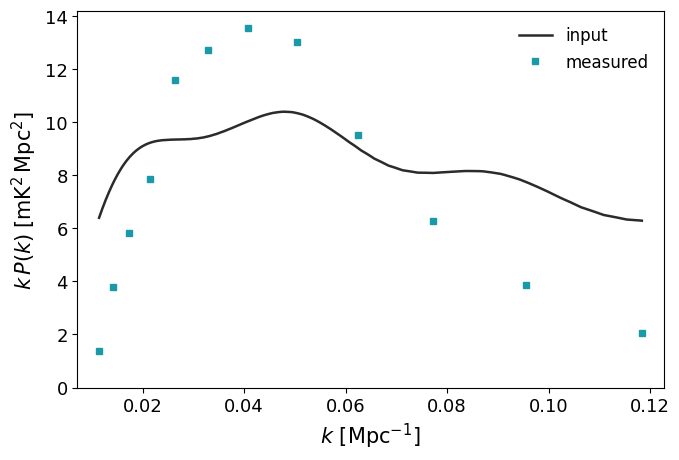

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(k_model, k_model * p_model * 1e6, "-", color="#2B2B2B", lw=1.8, label="input")
ax.plot(k_res, k_res * p_res * 1e6, "s", color="#1A9AA8", ms=5, label="measured")
ax.set_xlabel(r"$k\ [{\rm Mpc}^{-1}]$")
ax.set_ylabel(r"$k\,P(k)\;[{\rm mK^2\,Mpc^2}]$")
xpad = 0.04 * (k_res[-1] - k_res[0])   # small margin at both ends
ax.set_xlim(k_res[0] - xpad, k_res[-1] + xpad)
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
# plt.savefig("power_spectrum_kpk_model.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Model with observational effects and PCA signal loss

Now the model includes bias, RSD, beam, pixel and grid windows and the survey window, plus the PCA signal loss from the analytic transfer function.

In [14]:
from meer21cm.transfer import analytic_transfer_function

# model with bias, RSD, beam, pixel and grid windows and the survey window
mock.sampling_resol = [mock.pix_resol_in_mpc, mock.pix_resol_in_mpc, mock.los_resol_in_mpc]  # pixel and channel size [Mpc]
mock.compensate = [True, False]  # include the gridding window (HI only)
p_obs_3d = mock.auto_power_tracer_1_model

# PCA signal loss along the line of sight (the z axis of the box)
_, A_mat = pca_clean(obs_cube, 3, mean_center=True,
                     return_A=True)  # return_A: also return the removed modes
tf, _ = analytic_transfer_function(np.eye(nu.size) - A_mat @ A_mat.T)  # input: the cleaning matrix
k_para = 2 * np.pi * np.arange(tf.size) / (nu.size * mock.los_resol_in_mpc)  # k_parallel of each frequency mode [Mpc^-1]
p_cl_3d = p_obs_3d * np.interp(np.abs(mock.k_vec[2]), k_para, 1 / tf)  # keep the fraction 1/tf of the power at each |k_z|

**$k$ bins and cuts.** Linear $k$ bins, dropping the line-of-sight modes that PCA removes and the small transverse scales washed out by the beam.

In [15]:
kpara_min, kperp_max = 0.01, 0.08  # k cuts [Mpc^-1]
kcut = dict(
    k1dbins=np.arange(0.015, 0.1301, 0.005),  # linear k bins [Mpc^-1]
    k_perppara_min=[0.0, kpara_min],          # minimum (k_perp, |k_par|)
    k_perppara_max=[kperp_max, np.inf],       # maximum (k_perp, |k_par|)
)
p_res_cut, k_cut, nmodes_cut = mock.get_1d_power("auto_power_3d_1", **kcut)  # measured
p_mod_cut, _, _ = mock.get_1d_power(p_cl_3d, **kcut)                         # model

**Error bars.** Naive Gaussian errors, $\sigma_P = \sqrt{(P_{12}^2 + P_{11}P_{22})/2}\,/\sqrt{N_{\rm modes}}$, using the model power.

In [16]:
# auto spectrum: P_cross = P_auto1 = P_auto2 = model power
p_cross = p_auto1 = p_auto2 = p_mod_cut
sigma_p = np.sqrt((p_cross**2 + p_auto1 * p_auto2) / 2) / np.sqrt(nmodes_cut)

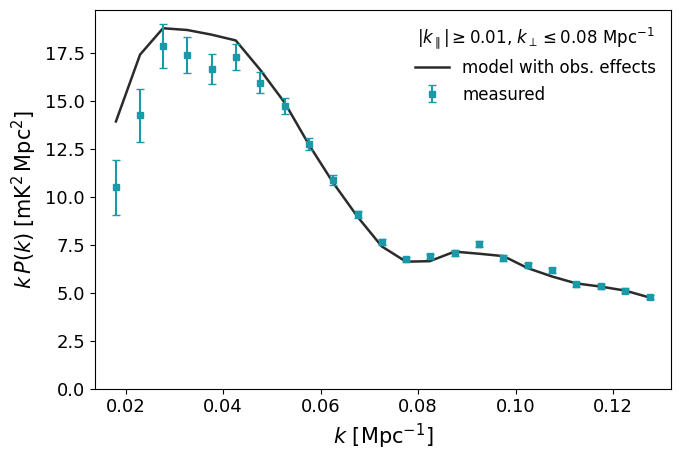

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(k_cut, k_cut * p_mod_cut * 1e6, "-", color="#2B2B2B", lw=1.8, label="model with obs. effects")
ax.errorbar(k_cut, k_cut * p_res_cut * 1e6, yerr=k_cut * sigma_p * 1e6,
            fmt="s", color="#1A9AA8", ms=5, elinewidth=1.5, capsize=3, label="measured")
ax.set_xlabel(r"$k\ [{\rm Mpc}^{-1}]$")
ax.set_ylabel(r"$k\,P(k)\;[{\rm mK^2\,Mpc^2}]$")
xpad = 0.04 * (k_cut[-1] - k_cut[0])   # small margin at both ends
ax.set_xlim(k_cut[0] - xpad, k_cut[-1] + xpad)
ax.set_ylim(bottom=0)
ax.legend(title=rf"$|k_\parallel| \geq {kpara_min}$, $k_\perp \leq {kperp_max}\ {{\rm Mpc}}^{{-1}}$")
fig.tight_layout()
# plt.savefig("power_spectrum_kpk_model_tf_kcut.png", dpi=200, bbox_inches="tight")
plt.show()

**Model vs measured.** With the observational effects and the PCA loss, the model follows the measurement, except in the lowest $k$ bins where PCA removes most of the power. This is an illustration only: it varies between realisations and is not a strict test.